<a href="https://colab.research.google.com/github/kingajutrzenka/Projekt-z-eksploracji-danych-World-Happiness-Report-2024/blob/main/Kod_w_google_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Raport o szczęściu na świecie 2024**

Zbiór danych zawiera informacje w podziale na kraje dotyczące poziomu szczęścia oraz czynnki mogące mieć na niego wpływ. Dane pochodzą z roku 2024 i zostały zebrane dzięki Gallup World Poll, czyli międzynarodowemu badaniu opinii i dobrostanu prowadzonemu przez instytut Gallup od 2005 roku.

Opis kolumn:

1. **Country name - Nazwa kraju**
2. **Regional indicator - Region**: Część świata, do której należy dany kraj.
3. **Ladder score - Wskaźnik szczęścia (wynik drabiny)**: Ocena zadowolenia z życia w skali od 0 (najgorsze możliwe życie) do 10 (najlepsze możliwe życie).
4. **Upper whisker - Górna granica błędu**: Maksymalna wartość wskaźnika szczęścia przy uwzględnieniu marginesu błędu statystycznego.
5. **Lower whisker - Dolna granica błędu**: Minimalna wartość wskaźnika szczęścia przy uwzględnieniu marginesu błędu statystycznego.
6. **Log GDP per capita - Zlogarytmowane PKB na osobę**: Wskaźnik zamożności kraju na jednego mieszkańca (uwzględniający lokalne ceny), podany w skali logarytmicznej, żeby łatwiej było porównywać kraje bardzo biedne z bardzo bogatymi.
7. **Social support - Wsparcie społeczne**: Odsetek osób w kraju, które deklarują, że w trudnej sytuacji mają rodzinę lub przyjaciół, na których mogą liczyć.
8. **Healthy life expectancy - Oczekiwana długość życia w zdrowiu**: Średnia liczba lat, jaką noworodek przeżyje w dobrej kondycji fizycznej i psychicznej (bez poważnych chorób).
9. **Freedom to make life choices - Wolność wyboru**: Poziom zadowolenia mieszkańców z tego, na ile swobodnie mogą decydować o swoim życiu.
10. **Generosity - Hojność (szczodrość)**: Skłonność mieszkańców do wpłacania pieniędzy na cele charytatywne, ale przeliczona tak, aby bogatsze kraje nie miały automatycznej przewagi nad biedniejszymi.
11. **Perceptions of corruption - Postrzeganie korupcji**: Ocena tego, jak bardzo skorumpowani w oczach obywateli są politycy oraz świat biznesu w danym kraju.
12. **Dystopia + residual - Dystopia + wartość resztowa**: Punkt odniesienia oparty na wymyślonym, najbardziej nieszczęśliwym kraju świata (Dystopii), powiększony o tę część wyniku szczęścia, której nie da się wyjaśnić pozostałymi zmiennymi z tabeli.
13. **Positive affect - Pozytywne emocje**: Średnia częstotliwość doświadczania dobrych emocji przez mieszkańców dnia poprzedniego.
14. **Negative affect - Negatywne emocje**: Średnia częstotliwość doświadczania trudnych emocji przez mieszkańców dnia poprzedniego.

Celem analizy jest sprawdzanie siły (poziomu korelcji) czynników zawartych w zbiorze na poziom szczęścia. Na tym zbiorze danych oparty jest World Happiness Report 2024, z tego względu pojawił się u nas pomysł o zbadaniu jak mocno dany czynnik wpływa na poziom szczęścia.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

‼ Uwaga, dane z usuniętymi brakami to d3

In [ ]:
dane = pd.read_csv("World-happiness-report-2024.csv")
dane.head()

,Country name,Regional indicator,Ladder score,upperwhisker,lowerwhisker,Log GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Dystopia + residual
0,Finland,Western Europe,7.741,7.815,7.667,1.844,1.572,0.695,0.859,0.142,0.546,2.082
1,Denmark,Western Europe,7.583,7.665,7.500,1.908,1.520,0.699,0.823,0.204,0.548,1.881
2,Iceland,Western Europe,7.525,7.618,7.433,1.881,1.617,0.718,0.819,0.258,0.182,2.050
3,Sweden,Western Europe,7.344,7.422,7.267,1.878,1.501,0.724,0.838,0.221,0.524,1.658
4,Israel,Middle East and North Africa,7.341,7.405,7.277,1.803,1.513,0.740,0.641,0.153,0.193,2.298


## **Podstawowe informacje o zbiorze danych**

**Wymiary zbioru**

In [ ]:
dane.shape

(143, 12)

Zbiór ma 143 wiersze i 12 kolumn

**Braki danych**

In [ ]:
dane.isnull().sum()


,0
Country name,0
Regional indicator,0
Ladder score,0
upperwhisker,0
lowerwhisker,0
Log GDP per capita,3
Social support,3
Healthy life expectancy,3
Freedom to make life choices,3
Generosity,3


W zbiorze występują po 3 braki danych w kolumnach: "Log GDP per capita", "Social support", "Healthy life expectancy", "Freedom to make life choices", "Generosity", "Perceptions of corruption" oraz "Dystopia + residual". Poza kolumną "Dystopia + residual" są to dane służące do badania ich wpływu na "Ladder score" (poziom szczęscia). Z tego względu sprawdzimy, gdzie te braki występują.

In [ ]:
dane[dane.isnull().any(axis=1)]

#wyświetla wiersze, gdzie jest przynajmniej jeden brak danych

,Country name,Regional indicator,Ladder score,upperwhisker,lowerwhisker,Log GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Dystopia + residual
61,Bahrain,Middle East and North Africa,5.959,6.153,5.766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
87,Tajikistan,Commonwealth of Independent States,5.281,5.361,5.201,NaN,NaN,NaN,NaN,NaN,NaN,NaN
102,State of Palestine,Middle East and North Africa,4.879,5.006,4.753,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Braki danych występują dla 3 kraji. W przypadku każdego kraju znamy poziom szczęścia, ale nie mamy danych które służą do badania wpływu czynników na poziom szczęścia. Jako, że celem tego projektu jest zbadania zależności między m.in. poziomem PKB per capita, a poziomem szczęścia, to nie użyjemy tych trzech krajów w dalszej analizie, ponieważ nie wnoszą one informacji do dalszego badania.

In [ ]:
d3 = dane.dropna()

In [ ]:
d3.shape

(140, 12)

**Typy danych**

In [ ]:
d3.dtypes

,0
Country name,object
Regional indicator,object
Ladder score,float64
upperwhisker,float64
lowerwhisker,float64
Log GDP per capita,float64
Social support,float64
Healthy life expectancy,float64
Freedom to make life choices,float64
Generosity,float64


W zbiorze mamy 2 kolumny z typem object - dane tekstowe: "Country name" oraz "Regional indicator". Reszta kolumn ma typ float64, czyli są to liczby zmiennoprzecinkowe.:

## **Badanie zależności**

Do badania wpływu czynników na poziom szczęścia nie przydadzą nam się kolumny : "Country name", "Regional indicator", "upperwhisker", "lowerwhisker" oraz "Dystopia + residual", dlatego też usunę je przed przejściem do badania korelacji

In [ ]:
dk = d3.drop(columns=["Country name", "Regional indicator", "upperwhisker", "lowerwhisker", "Dystopia + residual"])

Text(0.5, 1.0, 'Macierz korelacji czynników wpływu na poziom szczęścia')

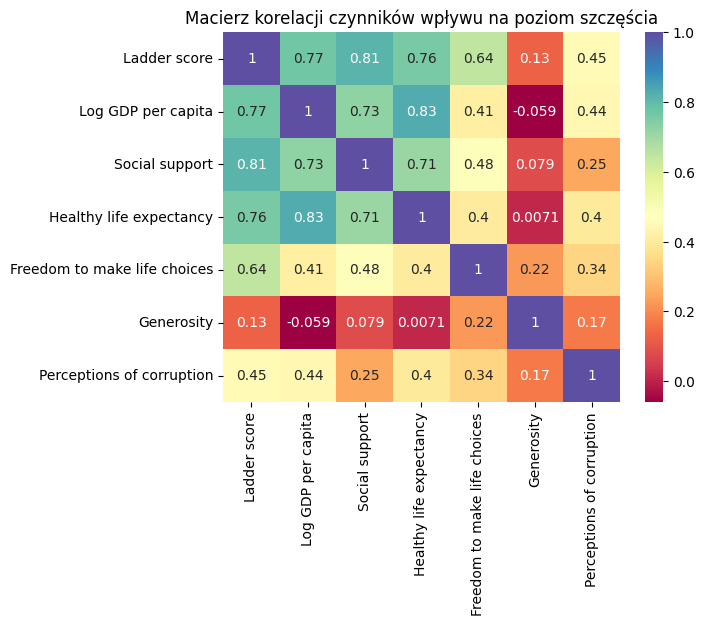

In [ ]:
corr = dk.corr(numeric_only=True)
sns.heatmap(corr, cmap="Spectral", annot=True)
plt.title("Macierz korelacji czynników wpływu na poziom szczęścia")

Siła korelacji pomiędzy poziomem szczęścia, a czynnikami wpływu (interpretacja wg. J. Giulforda):
- Zlogarytmowane PKB na osobę: 0.77 - bardzo wysoka korelacja dodatnia
- Wsparcie społeczne: 0.81 -  bardzo wysoka korelacja dodatnia
- Oczekiwana długość życia w zdrowiu: 0.76 - bardzo wysoka korelacja dodatnia
- Wolność wyboru: 0.64 - wysoka korelacja dodatnia
- Hojność : 0.13 - słaba korelacja dodatnia
- Postrzeganie korupcji:0.45 - umiarkowana korelacja dodatnia

### Przedstawienie wartości zmiennych i objaśnienie zbioru badanego



In [ ]:
tab_kraj=d3['Country name'].unique()
tab_kraj

array(['Finland', 'Denmark', 'Iceland', 'Sweden', 'Israel', 'Netherlands',
       'Norway', 'Luxembourg', 'Switzerland', 'Australia', 'New Zealand',
       'Costa Rica', 'Kuwait', 'Austria', 'Canada', 'Belgium', 'Ireland',
       'Czechia', 'Lithuania', 'United Kingdom', 'Slovenia',
       'United Arab Emirates', 'United States', 'Germany', 'Mexico',
       'Uruguay', 'France', 'Saudi Arabia', 'Kosovo', 'Singapore',
       'Taiwan Province of China', 'Romania', 'El Salvador', 'Estonia',
       'Poland', 'Spain', 'Serbia', 'Chile', 'Panama', 'Malta', 'Italy',
       'Guatemala', 'Nicaragua', 'Brazil', 'Slovakia', 'Latvia',
       'Uzbekistan', 'Argentina', 'Kazakhstan', 'Cyprus', 'Japan',
       'South Korea', 'Philippines', 'Vietnam', 'Portugal', 'Hungary',
       'Paraguay', 'Thailand', 'Malaysia', 'China', 'Honduras', 'Croatia',
       'Greece', 'Bosnia and Herzegovina', 'Libya', 'Jamaica', 'Peru',
       'Dominican Republic', 'Mauritius', 'Moldova', 'Russia', 'Bolivia',
       'Ecua

Wykres pokazuje na mapie świata jakie kraje wzięły udział w badaniu

In [ ]:
import numpy as np
import plotly.express as px
wyk=px.choropleth(locations=tab_kraj, locationmode='country names', color=[1]*len(tab_kraj),color_continuous_scale=['#00CED1','#00CED1'],title='Kraje występujące w analizowanych zbiorze')
wyk.update_layout(coloraxis_showscale=False)
wyk.show()

Wykres pokazuje, że nasz zbiór danych zawiera wyniki ze znakomitej większości krajów świata.

### Średnia logarytmu PKB na mieszkańca z podziałem na regiony

In [ ]:
# obliczanie średniego PKB według regionu
sr=d3.groupby('Regional indicator', as_index=False)['Log GDP per capita'].mean()
# zaokrąglenie wyników i sortowanie malejąco
sr['Log GDP per capita']=sr['Log GDP per capita'].round(2)
sr=sr.sort_values(by='Log GDP per capita',ascending=False)
# wyswietlenie tabelki potrzebnej do sporządzenia wykresu
print(sr.to_string(index=False))

                Regional indicator  Log GDP per capita
                    Western Europe                1.87
             North America and ANZ                1.86
                         East Asia                1.70
        Central and Eastern Europe                1.64
      Middle East and North Africa                1.46
Commonwealth of Independent States                1.40
                    Southeast Asia                1.37
       Latin America and Caribbean                1.33
                        South Asia                1.05
                Sub-Saharan Africa                0.90


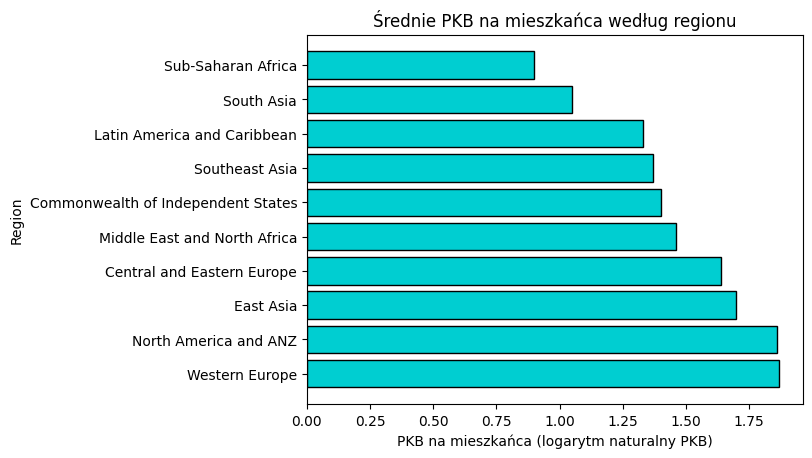

In [ ]:
import matplotlib.pyplot as plt
# wykres
plt.barh(sr['Regional indicator'],sr['Log GDP per capita'],color='darkturquoise', edgecolor='black')
# tytuł i opisy
plt.title('Średnie PKB na mieszkańca według regionu')
plt.ylabel('Region')
plt.xlabel('PKB na mieszkańca (logarytm naturalny PKB)')
plt.show()

Wykres dobrze szacuje nam przeciętną zamożność społeczeństwa.Do najbardziej zamożnych należy społeczeństwo wschodniej Europy, zaś do najmniej zamożnych należy społeczństwo subsaharyjskiej Afryki.

### Długość życia noworodka w zdrowiu z podziałem na regiony

In [ ]:
wykr=px.violin(d3,x='Regional indicator', y='Healthy life expectancy',color='Regional indicator',box=True, points='all',hover_name='Country name',title='Gęstość i rozkład długości życia noworodka w zdrowiu z podziałem na regiony')
wykr.update_layout(showlegend=False)
wykr.update_layout(title="Długość życia w zdrowiu według regionów<br><sub>Wartości znormalizowane w skali od 0 do 1</sub>")
wykr.show()

Na tym wykresie widzimy, że długość życia noworodka w zdrowiu jest dość bardzo zróżnicowana w poszczególnych regionach świata. Na przykład w zachodniej Azji mediana długości życia noworodka w zdrowiu jest największa, jednak kraj ten posiada również wartości znacznie odstające od mediany. Za to w centralnej i zachodniej Europie długość życia noworodka w zdrowiu jest zbliżona w całym regionie.

### Wolność dokonywania wyborów w krajach świata potrzegana przez obywateli krajów świata

In [ ]:
import numpy as np
import plotly.express as px
wyk=px.choropleth(data_frame=d3, locations=tab_kraj, locationmode='country names', color='Freedom to make life choices',color_continuous_scale='Viridis',title='Wolność dokonywania wyborów według obywateli poszczególnych krajów świata')
wyk.show()

Wykres bardzo jasno przedstawia jak postrzegają swoją wolność wyboru obywatele poszczególnych krajów świata. Najbardziej cieszą się wolnością mieszkańcy Szwecji, Norwegii, Finlandii, Uzbekistanu, Kirgistanu oraz Kambodży. Mieszkańcy Afganistanu i Algierii uważają, że ich wolność wyboru jest bardzo ograniczona.

### Wsparcie społeczne według obywateli poszczególnych krajów świata (posiadanie przyjaciół/krewnych, na których mogą liczyć)

In [ ]:
import numpy as np
import plotly.express as px
wyk=px.choropleth(data_frame=d3, locations=tab_kraj, locationmode='country names', color='Social support',color_continuous_scale='Viridis',title='Wsparcie społeczne według obywateli poszczególnych krajów świata (posiadanie przyjaciół/krewnych, na których mogą liczyć)')
wyk.show()

Wykres przedstawia jak obywatele poszczególnych krajów świata odczuwają wsparcie społeczne - swojej rodziny lub krewnych. Najbardziej cieszą się wsparciem krewnych mieszkańcy Finlandi i Islandi. Mieszkańcy Afganistanu, Beninu i Bangladeszu uważają, że nie rzadko mogą liczyć na wsparcie najbliższych.

### Przekazywanie pieniędzy na cele charytatywne w odniesieniu do PKB na mieszkańca.

In [ ]:
import numpy as np
import plotly.express as px
wyk=px.choropleth(data_frame=d3, locations=tab_kraj, locationmode='country names', color='Generosity',color_continuous_scale='Viridis',title='Przekazywanie pieniędzy na cele charytatywne w odniesieniu do PKB na mieszkańca.')
wyk.show()

Wykres ciekawie pokazuje hojność obywateli świata. Większość globu pokrywa kolor granatowy co świadczy o małej hojności ludzi. Jednak są zaskakujące odstępstwa. Indonezja i Birma to chyba najbardziej hojne kraje świata. Do najmniej hojnych należą miedzy innymi Botsawana (jednak tu, myślę, że czynnikim może być bieda) oraz Egipt.

### Percepcja korupcji

In [ ]:
import numpy as np
import plotly.express as px
wyk=px.choropleth(data_frame=d3, locations=tab_kraj, locationmode='country names', color='Perceptions of corruption',color_continuous_scale='Viridis',title='Percepcja korupcji w krajach świata')
wyk.show()

Obywatele Finlandi uważają, że ich rząd i przedsiębiorstwa nie są skorumpowane, jednak znaczna część świata uważa swój kraj za nieuczciwy i plamiący się korupcją (np.: Peru, Nigeria i Rumunia)

### Jak odbierasz swój kraj prównując go do kraju dystopijnego - najgorszego jaki może istanieć?

In [ ]:
import numpy as np
import plotly.express as px
wyk=px.choropleth(data_frame=d3, locations=tab_kraj, locationmode='country names', color='Dystopia + residual',color_continuous_scale='Viridis',title='Postrzeganie stanu swojego kraju w porównaniu z krajem dystopijnym')
wyk.show()

Najszczęsliwszym krajem, prównując do najgorszego kraju jaki może być, jest Wenezuela, a krajami najbliższymi dystopii są Botsawana i Sri Lanka.

In [ ]:
# @title ☀️ Interaktywny Raport o Szczęściu 2024 (Projekt) {display-mode: "form"}
import json
from IPython.display import display, HTML
from google.colab import output
import pandas as pd
import numpy as np

def _report_js_error(message):
    print(f"JavaScript Error: {message}")

output.register_callback('report_js_error', _report_js_error)

# Prepare Data
if 'd3' in globals() and 'dk' in globals():
    data_json = d3.to_json(orient='records')
    # Calculate correlation matrix
    corr_matrix = dk.corr(numeric_only=True).round(2)
    corr_json = corr_matrix.to_json(orient='split')

    # Regional averages for the bar chart
    sr = d3.groupby('Regional indicator', as_index=False)['Log GDP per capita'].mean()
    sr['Log GDP per capita'] = sr['Log GDP per capita'].round(2)
    sr = sr.sort_values(by='Log GDP per capita', ascending=False)
    sr_json = sr.to_json(orient='records')
else:
    data_json = "[]"
    corr_json = "{}"
    sr_json = "[]"

html_template = """
<!DOCTYPE html>
<html lang="pl">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Raport o Szczęściu na Świecie 2024</title>
    <!-- Plotly for maps -->
    <script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
    <!-- Chart.js for other charts -->
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <!-- Chart.js Datalabels Plugin -->
    <script src="https://cdn.jsdelivr.net/npm/chartjs-plugin-datalabels@2.2.0"></script>
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@300;400;600;700&display=swap" rel="stylesheet">
    <style>
        :root {
            --bg-color: #ffffff;
            --page-bg: #fdfdfd;
            --text-main: #2c3e50;
            --text-muted: #5a6c7d;
            --accent-yellow: #F1C40F;
            --accent-gold: #D4AC0D;
            --border-radius: 16px;
            --shadow: 0 8px 16px rgba(241, 196, 15, 0.1);
            --tab-active: #FFF9E6;
        }
        body {
            font-family: 'Inter', sans-serif;
            background-color: var(--page-bg);
            color: var(--text-main);
            margin: 0;
            padding: 20px;
            line-height: 1.7;
        }
        .dashboard-container {
            max-width: 1200px;
            margin: 0 auto;
        }
        .header-section {
            background: var(--bg-color);
            padding: 35px;
            border-radius: var(--border-radius);
            box-shadow: var(--shadow);
            margin-bottom: 24px;
            border-left: 8px solid var(--accent-yellow);
            position: relative;
            overflow: hidden;
        }
        .header-section::after {
            content: '☀️';
            position: absolute;
            right: -20px;
            top: -30px;
            font-size: 150px;
            opacity: 0.05;
        }
        .header-section h1 {
            margin-top: 0;
            font-size: 2.4rem;
            color: #1a252f;
            font-weight: 700;
            letter-spacing: -0.5px;
        }
        .text-content {
            background: var(--bg-color);
            padding: 30px;
            border-radius: var(--border-radius);
            box-shadow: var(--shadow);
            margin-bottom: 24px;
        }
        .text-content h3 {
            margin-top: 0;
            color: var(--accent-gold);
            border-bottom: 2px solid var(--accent-yellow);
            display: inline-block;
            padding-bottom: 5px;
            font-size: 1.4rem;
        }
        .text-content p {
            color: var(--text-muted);
            font-size: 1.05rem;
        }

        /* Tabs Styling */
        .tabs {
            display: flex;
            gap: 12px;
            margin-bottom: 24px;
            flex-wrap: wrap;
        }
        .tab-btn {
            padding: 12px 24px;
            border: 2px solid transparent;
            background: #f4f6f7;
            border-radius: 12px;
            cursor: pointer;
            font-family: 'Inter', sans-serif;
            font-weight: 600;
            font-size: 1.05rem;
            color: var(--text-muted);
            transition: all 0.3s ease;
        }
        .tab-btn:hover {
            background: #FEF9E7;
            color: var(--accent-gold);
        }
        .tab-btn.active {
            background: var(--tab-active);
            border-color: var(--accent-yellow);
            color: var(--accent-gold);
            box-shadow: 0 4px 8px rgba(241, 196, 15, 0.15);
        }
        .tab-content {
            display: none;
            animation: fadeIn 0.5s ease-out;
        }
        .tab-content.active {
            display: block;
        }
        @keyframes fadeIn {
            from { opacity: 0; transform: translateY(10px); }
            to { opacity: 1; transform: translateY(0); }
        }

        .chart-card {
            background: var(--bg-color);
            padding: 25px;
            border-radius: var(--border-radius);
            box-shadow: var(--shadow);
            margin-bottom: 24px;
        }
        .chart-card h3 {
            color: var(--text-main);
            margin-top: 0;
            margin-bottom: 10px;
        }
        .chart-card p {
            color: var(--text-muted);
            font-size: 0.95rem;
            margin-bottom: 20px;
        }
        .canvas-wrapper {
            position: relative;
            flex-grow: 1;
            min-height: 0;
            height: 450px;
            width: 100%;
        }
        .map-wrapper {
            height: 500px;
            width: 100%;
            border-radius: 12px;
            overflow: hidden;
            border: 1px solid #f0f3f4;
        }

        /* Correlation Matrix Table */
        .corr-table-container {
            overflow-x: auto;
            border-radius: 8px;
        }
        table {
            width: 100%;
            border-collapse: collapse;
            margin-top: 15px;
            font-size: 0.95rem;
        }
        th, td {
            padding: 12px;
            text-align: center;
            border: 1px solid #eef2f5;
        }
        th {
            background-color: #fcfcfc;
            font-weight: 600;
            color: var(--text-main);
            text-align: left;
        }
        td.corr-val {
            font-weight: 700;
            color: #2c3e50;
        }

        ul {
            padding-left: 20px;
            color: var(--text-muted);
        }
        li {
            margin-bottom: 10px;
        }
        .highlight {
            font-weight: 700;
            color: var(--accent-gold);
            background: #FEF9E7;
            padding: 2px 6px;
            border-radius: 4px;
        }
    </style>
</head>
<body>
    <div class="dashboard-container">

        <div class="header-section">
            <h1>Raport o Szczęściu na Świecie 2024 🌍</h1>
            <p>Eksploracja zbioru danych zawierającego informacje o poziomie szczęścia w poszczególnych krajach oraz czynnikach, które mogą mieć na niego kluczowy wpływ. Dane pochodzą z międzynarodowego badania opinii <strong>Gallup World Poll (2024)</strong>.</p>
            <h3 style="margin-top: 20px; border:none; padding:0;">🎯 Cel badawczy</h3>
            <p style="margin-bottom: 0;">Głównym celem analizy jest zbadanie siły korelacji między dostępnymi czynnikami społeczno-ekonomicznymi a ostatecznym poziomem zadowolenia z życia obywateli. Chcemy sprawdzić, co tak naprawdę czyni nas szczęśliwymi.</p>
        </div>

        <!-- Nawigacja Zakładek -->
        <div class="tabs">
            <button class="tab-btn active" onclick="openTab(event, 'tab-wstep')">📖 Wstęp i Słownik</button>
            <button class="tab-btn" onclick="openTab(event, 'tab-korelacja')">📊 Macierz Korelacji</button>
            <button class="tab-btn" onclick="openTab(event, 'tab-mapy')">🗺️ Mapy Świata</button>
            <button class="tab-btn" onclick="openTab(event, 'tab-regiony')">📈 Analiza Regionów</button>
        </div>

        <!-- ZAKŁADKA 1: Wstęp -->
        <div id="tab-wstep" class="tab-content active">
            <div class="text-content">
                <h3>Opis zmiennych objaśniających (słownik pojęć)</h3>
                <div style="columns: 2 300px; gap: 40px; font-size: 0.95rem; color: #5a6c7d;">
                    <p><strong>Ladder score:</strong> Ocena zadowolenia z życia w skali od 0 do 10 (główny wskaźnik szczęścia).</p>
                    <p><strong>Log GDP per capita:</strong> Wskaźnik zamożności kraju na jednego mieszkańca podany w skali logarytmicznej.</p>
                    <p><strong>Social support:</strong> Odsetek osób deklarujących, że w trudnej sytuacji mają na kogo liczyć.</p>
                    <p><strong>Healthy life expectancy:</strong> Średnia liczba lat przeżyta w dobrej kondycji fizycznej i psychicznej.</p>
                    <p><strong>Freedom to make life choices:</strong> Poziom zadowolenia ze swobody decydowania o swoim życiu.</p>
                    <p><strong>Generosity:</strong> Skłonność mieszkańców do wpłacania pieniędzy na cele charytatywne.</p>
                    <p><strong>Perceptions of corruption:</strong> Ocena poziomu korupcji w świecie biznesu i polityki w danym kraju.</p>
                    <p><strong>Dystopia + residual:</strong> Punkt odniesienia oparty na hipotetycznym najgorszym kraju świata.</p>
                </div>
            </div>
            <div class="chart-card">
                <h3>Zasięg geograficzny badania</h3>
                <p>Nasz zbiór danych obejmuje zdecydowaną większość krajów na kuli ziemskiej, co pozwala na rzetelną, globalną analizę dobrostanu.</p>
                <div id="map-all" class="map-wrapper"></div>
            </div>
        </div>

        <!-- ZAKŁADKA 2: Korelacja -->
        <div id="tab-korelacja" class="tab-content">
            <div class="chart-card">
                <h3>Macierz korelacji: Co wpływa na szczęście?</h3>
                <p>Tabela przedstawia siłę powiązań między poszczególnymi zmiennymi. Odcienie złota i żółci identyfikują najsilniejsze korelacje (ciemniejszy złoty = silna korelacja dodatnia).</p>
                <div class="corr-table-container" id="corr-table-div"></div>
            </div>

            <div class="text-content">
                <h3>Kluczowe wnioski (Interpretacja J. Giulforda)</h3>
                <ul>
                    <li><span class="highlight">Wsparcie społeczne (0.81)</span> - Bardzo wysoka korelacja dodatnia. Bliskość i wsparcie bliskich okazują się najważniejszym czynnikiem warunkującym szczęście!</li>
                    <li><span class="highlight">Zamożność (PKB per capita) (0.77)</span> - Bardzo wysoka korelacja. Bogactwo państwa bezsprzecznie rzutuje na zadowolenie obywateli.</li>
                    <li><span class="highlight">Oczekiwana długość życia w zdrowiu (0.76)</span> - Bardzo silny związek ze szczęściem.</li>
                    <li><span class="highlight">Wolność wyboru (0.64)</span> - Wysoka korelacja dodatnia. Poczucie sprawczości jest dla nas niezwykle ważne.</li>
                    <li><span class="highlight">Postrzeganie korupcji (0.45)</span> - Umiarkowana korelacja dodatnia.</li>
                    <li><span class="highlight">Hojność (0.13)</span> - Słaba korelacja dodatnia. Wpływa na zadowolenie najmniej spośród badanych cech.</li>
                </ul>
            </div>

            <div class="chart-card">
                <h3>Zależność: Zamożność a Zadowolenie z życia</h3>
                <p>Poniższy wykres punktowy świetnie obrazuje bardzo silną dodatnią korelację (r = 0.77). Wyraźnie widać, że wraz ze wzrostem PKB rośnie wskaźnik szczęścia.</p>
                <div class="canvas-wrapper">
                    <canvas id="scatterChart"></canvas>
                </div>
            </div>
        </div>

        <!-- ZAKŁADKA 3: Mapy -->
        <div id="tab-mapy" class="tab-content">
            <div class="chart-card">
                <h3>🕊️ Wolność dokonywania wyborów</h3>
                <p>Największym poczuciem wolności cieszą się mieszkańcy m.in. Szwecji, Norwegii, Finlandii czy Uzbekistanu. Na przeciwnym biegunie (ciemniejsze barwy) znajdują się Afganistan i Algieria, gdzie swoboda jest mocno ograniczona.</p>
                <div id="map-freedom" class="map-wrapper"></div>
            </div>

            <div class="chart-card">
                <h3>🤝 Wsparcie społeczne (Rodzina i przyjaciele)</h3>
                <p>Skandynawia (Finlandia, Islandia) przoduje w poczuciu oparcia w bliskich. Wskaźnik ten jest znacznie niższy w krajach takich jak Afganistan czy Benin.</p>
                <div id="map-social" class="map-wrapper"></div>
            </div>

            <div class="chart-card">
                <h3>💝 Hojność (Skłonność do pomocy charytatywnej)</h3>
                <p>Ciekawy przypadek odstający od normy: większość globu wykazuje niski wskaźnik hojności w stosunku do PKB, jednak kraje takie jak Indonezja czy Birma (Mjanma) wyróżniają się niesamowitą szczodrością obywateli.</p>
                <div id="map-generosity" class="map-wrapper"></div>
            </div>

            <div class="chart-card">
                <h3>⚖️ Percepcja korupcji w państwie</h3>
                <p>Podczas gdy obywatele Finlandii postrzegają swoje państwo jako wysoce uczciwe, znaczna część świata boryka się z głębokim przekonaniem o skorumpowaniu swoich rządów i przedsiębiorstw.</p>
                <div id="map-corruption" class="map-wrapper"></div>
            </div>

            <div class="chart-card">
                <h3>🌑 Dystopia + residual (Punkt odniesienia)</h3>
                <p>Wenezuela jawi się jako najszczęśliwszy kraj względem najgorszego możliwego wariantu dystopijnego, podczas gdy Botswana i Sri Lanka znajdują się niebezpiecznie blisko dna tej skali.</p>
                <div id="map-dystopia" class="map-wrapper"></div>
            </div>
        </div>

        <!-- ZAKŁADKA 4: Regiony -->
        <div id="tab-regiony" class="tab-content">
            <div class="chart-card">
                <h3>Średnie PKB na mieszkańca według regionów świata</h3>
                <p>Wykres szacujący przeciętną zamożność. Społeczeństwa Zachodniej Europy i Ameryki Północnej zdecydowanie dominują ekonomicznie, podczas gdy Afryka Subsaharyjska pozostaje najbardziej ubogim regionem.</p>
                <div class="canvas-wrapper">
                    <canvas id="barRegionChart"></canvas>
                </div>
            </div>

            <div class="chart-card">
                <h3>Oczekiwana długość życia w zdrowiu (Rozkład wg regionów)</h3>
                <p>Długość życia noworodka jest mocno zróżnicowana globalnie. Wykres skrzypcowy ukazuje, jak stabilna pod tym względem jest Europa Zachodnia, w przeciwieństwie np. do Azji Południowej o szerokim rozstrzale wyników.</p>
                <div id="violin-health" class="map-wrapper"></div>
            </div>
        </div>

    </div>

    <script>
        window.onerror = function(message) {
            if(typeof google !== 'undefined') {
                google.colab.kernel.invokeFunction('report_js_error', [message], {});
            }
            console.error(message);
        };

        // Register the DataLabels plugin for Chart.js
        Chart.register(ChartDataLabels);

        // Tab Logic
        function openTab(evt, tabName) {
            var i, tabcontent, tablinks;
            tabcontent = document.getElementsByClassName("tab-content");
            for (i = 0; i < tabcontent.length; i++) {
                tabcontent[i].style.display = "none";
                tabcontent[i].classList.remove("active");
            }
            tablinks = document.getElementsByClassName("tab-btn");
            for (i = 0; i < tablinks.length; i++) {
                tablinks[i].classList.remove("active");
            }
            document.getElementById(tabName).style.display = "block";
            document.getElementById(tabName).classList.add("active");
            evt.currentTarget.classList.add("active");

            // Trigger Plotly resize when tab becomes visible
            window.dispatchEvent(new Event('resize'));
        }

        // Injected Data
        const data = DATA_PLACEHOLDER;
        const corrData = CORR_PLACEHOLDER;
        const srData = SR_PLACEHOLDER;

        // Yellow/Gold Custom Colorscale for Maps
        const happinessScale = [
            [0, '#FEF9E7'],
            [0.2, '#F9E79F'],
            [0.5, '#F1C40F'],
            [0.8, '#D4AC0D'],
            [1, '#9A7D0A']
        ];

        if (data && data.length > 0) {

            // --- ZAKŁADKA 2: KORELACJA ---
            if(corrData && corrData.columns && corrData.data) {
                let tableHtml = '<table><thead><tr><th>Zmienna</th>';
                corrData.columns.forEach(col => {
                    tableHtml += `<th>${col}</th>`;
                });
                tableHtml += '</tr></thead><tbody>';

                // Aesthetic Yellow/Gold Color Scale for Correlation Matrix
                function getColor(val) {
                    if (val === 1) return 'rgba(212, 172, 13, 0.6)'; // Strong Gold
                    if (val > 0.7) return 'rgba(241, 196, 15, 0.5)'; // Yellow
                    if (val > 0.4) return 'rgba(249, 231, 159, 0.6)'; // Light Yellow
                    if (val > 0) return 'rgba(254, 249, 231, 0.8)'; // Very Light Yellow
                    return 'rgba(236, 240, 241, 0.5)'; // Neutral/Gray for negative
                }

                corrData.index.forEach((rowName, i) => {
                    tableHtml += `<tr><th>${rowName}</th>`;
                    corrData.data[i].forEach(val => {
                        let bg = getColor(val);
                        tableHtml += `<td class="corr-val" style="background-color: ${bg}">${val.toFixed(2)}</td>`;
                    });
                    tableHtml += '</tr>';
                });
                tableHtml += '</tbody></table>';
                document.getElementById('corr-table-div').innerHTML = tableHtml;
            }

            // Scatter Chart (Yellow/Gold)
            const scatterData = data.map(d => ({
                x: d['Log GDP per capita'],
                y: d['Ladder score'],
                country: d['Country name']
            })).filter(d => d.x != null && d.y != null);

            new Chart(document.getElementById('scatterChart').getContext('2d'), {
                type: 'scatter',
                data: {
                    datasets: [{
                        label: 'Kraje',
                        data: scatterData,
                        backgroundColor: 'rgba(241, 196, 15, 0.7)',
                        borderColor: '#D4AC0D',
                        borderWidth: 1,
                        pointRadius: 6,
                        pointHoverRadius: 9,
                        pointHoverBackgroundColor: '#9A7D0A'
                    }]
                },
                options: {
                    responsive: true,
                    maintainAspectRatio: false,
                    plugins: {
                        datalabels: { display: false }, // Hide datalabels for scatter
                        tooltip: {
                            backgroundColor: 'rgba(44, 62, 80, 0.9)',
                            titleFont: { size: 14 },
                            bodyFont: { size: 13 },
                            padding: 12,
                            callbacks: {
                                label: function(context) {
                                    return context.raw.country + ' | PKB: ' + context.raw.x.toFixed(2) + ' | Szczęście: ' + context.raw.y.toFixed(2);
                                }
                            }
                        },
                        legend: { display: false }
                    },
                    scales: {
                        x: { title: { display: true, text: 'Zamożność (Zlogarytmowane PKB per capita)', font: {weight: 'bold'} } },
                        y: { title: { display: true, text: 'Wskaźnik Szczęścia', font: {weight: 'bold'} } }
                    }
                }
            });

            // --- ZAKŁADKA 3: MAPY (Plotly) ---
            const locations = data.map(d => d['Country name']);

            function createMap(divId, zCol, title) {
                const zData = data.map(d => d[zCol]);
                const trace = {
                    type: 'choropleth',
                    locationmode: 'country names',
                    locations: locations,
                    z: zData,
                    text: locations,
                    hovertemplate: '<b>%{text}</b><br>Wartość: %{z:.2f}<extra></extra>',
                    colorscale: happinessScale,
                    colorbar: { title: '', thickness: 12 }
                };
                const layout = {
                    geo: {
                        projection: { type: 'natural earth' },
                        showframe: false,
                        showcoastlines: true,
                        coastlinecolor: '#eee',
                        countrycolor: '#dcdcdc'
                    },
                    margin: { l: 0, r: 0, t: 10, b: 0 },
                    paper_bgcolor: 'transparent',
                    plot_bgcolor: 'transparent'
                };
                Plotly.newPlot(divId, [trace], layout, {responsive: true});
            }

            // Map 1: All countries (Uniform Yellow)
            Plotly.newPlot('map-all', [{
                type: 'choropleth',
                locationmode: 'country names',
                locations: locations,
                z: locations.map(() => 1),
                text: locations,
                hovertemplate: '<b>%{text}</b><br>Kraj uwzględniony w badaniu<extra></extra>',
                colorscale: [[0, '#F1C40F'], [1, '#F1C40F']],
                showscale: false
            }], {
                geo: {
                    projection: { type: 'natural earth' },
                    showframe: false,
                    showcoastlines: true,
                    coastlinecolor: '#eee',
                    countrycolor: '#dcdcdc'
                },
                margin: { l: 0, r: 0, t: 10, b: 0 },
                paper_bgcolor: 'transparent'
            }, {responsive: true});

            createMap('map-freedom', 'Freedom to make life choices', 'Wolność dokonywania wyborów');
            createMap('map-social', 'Social support', 'Wsparcie społeczne');
            createMap('map-generosity', 'Generosity', 'Hojność');
            createMap('map-corruption', 'Perceptions of corruption', 'Percepcja korupcji');
            createMap('map-dystopia', 'Dystopia + residual', 'Dystopia + residual');

            // --- ZAKŁADKA 4: REGIONY ---
            if(srData && srData.length > 0) {
                new Chart(document.getElementById('barRegionChart').getContext('2d'), {
                    type: 'bar',
                    data: {
                        labels: srData.map(d => d['Regional indicator']),
                        datasets: [{
                            label: 'Średnie PKB (log)',
                            data: srData.map(d => d['Log GDP per capita']),
                            backgroundColor: '#F1C40F',
                            borderColor: '#D4AC0D',
                            borderWidth: 1,
                            borderRadius: 6,
                            barPercentage: 0.7
                        }]
                    },
                    options: {
                        indexAxis: 'y',
                        responsive: true,
                        maintainAspectRatio: false,
                        plugins: {
                            legend: { display: false },
                            datalabels: {
                                color: '#2c3e50',
                                anchor: 'end',
                                align: 'end',
                                font: { weight: 'bold', size: 12 },
                                formatter: function(value) { return value.toFixed(2); }
                            },
                            tooltip: {
                                backgroundColor: 'rgba(44, 62, 80, 0.9)',
                                padding: 12,
                                callbacks: {
                                    label: function(context) { return 'Średnie PKB: ' + context.raw.toFixed(2); }
                                }
                            }
                        },
                        scales: {
                            x: {
                                title: { display: true, text: 'PKB na mieszkańca (log)', font: {weight: 'bold'} },
                                suggestedMax: 2.2 // Zapas na etykiety
                            }
                        }
                    }
                });
            }

            // Violin Plot (Plotly - Yellow theme)
            const regions = [...new Set(data.map(d => d['Regional indicator']))];
            const violinData = regions.map(region => {
                const regionData = data.filter(d => d['Regional indicator'] === region);
                return {
                    type: 'violin',
                    y: regionData.map(d => d['Healthy life expectancy']),
                    name: region,
                    box: { visible: true },
                    meanline: { visible: true },
                    points: 'all',
                    text: regionData.map(d => d['Country name']),
                    hovertemplate: '<b>%{text}</b><br>Wartość: %{y:.2f}<extra></extra>',
                    line: { color: '#D4AC0D' },
                    fillcolor: '#F9E79F',
                    opacity: 0.8
                };
            });
            Plotly.newPlot('violin-health', violinData, {
                yaxis: { title: 'Oczekiwana długość życia (w zdrowiu)' },
                margin: { l: 60, r: 20, t: 20, b: 120 },
                showlegend: false,
                paper_bgcolor: 'transparent',
                plot_bgcolor: '#fdfdfd'
            }, {responsive: true});

        } else {
            console.error("Brak danych.");
        }
    </script>
</body>
</html>
"""

# Wstrzyknięcie zrzutu JSON danych do szablonu HTML
html_code = html_template.replace('DATA_PLACEHOLDER', data_json)
html_code = html_code.replace('CORR_PLACEHOLDER', corr_json)
html_code = html_code.replace('SR_PLACEHOLDER', sr_json)

# Wyświetlenie wyrenderowanego dashboardu
display(HTML(html_code))
